Antes de entrenar, una decisión importante: cómo dividir los datos
Para entrenar un modelo necesitas separar los datos en entrenamiento (con los que aprende) y test (con los que lo evalúas, datos que no ha visto). Pero no podemos hacer la división al azar, y esto es importante que lo entiendas:
Si dividimos al azar, podría pasar que el 29 de octubre de Chiva esté en entrenamiento y el 29 de octubre de Buñol (al lado) esté en test. Como son del mismo evento y están pegados, el modelo "haría trampa": habría visto algo casi idéntico. Las métricas saldrían infladas.
La solución correcta para datos espacio-temporales: dividir por tiempo. Entrenamos con los eventos más antiguos y validamos con los más recientes. Así el modelo se evalúa de verdad sobre eventos que no ha visto nunca.
Te propongo:

Entrenamiento: 2020 a 2023
Test: 2024 (incluye la DANA — el examen más exigente posible)

In [1]:
import pandas as pd

dataset = pd.read_parquet("../data/processed/dataset_etiquetado.parquet")
dataset["fecha"] = pd.to_datetime(dataset["fecha"])

# Features que usará el modelo (las columnas predictoras)
features = [
    "precip_dia", "precip_3d", "precip_7d", "precip_previa_7d",
    "elevacion", "pendiente", "mes", "temporada_lluvias",
]
target = "riesgo"

# División temporal: entrenamiento (2020-2023) vs test (2024)
train = dataset[dataset["fecha"].dt.year <= 2023]
test  = dataset[dataset["fecha"].dt.year == 2024]

X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print(f"Entrenamiento: {len(X_train):,} filas — {y_train.sum()} de riesgo ({y_train.mean()*100:.1f}%)")
print(f"Test (2024):   {len(X_test):,} filas — {y_test.sum()} de riesgo ({y_test.mean()*100:.1f}%)")

Entrenamiento: 15,044 filas — 444 de riesgo (3.0%)
Test (2024):   4,703 filas — 146 de riesgo (3.1%)


El 3% de riesgo se mantiene en ambos grupos — eso significa que la división temporal es representativa. Y tienes 146 casos de riesgo en test, suficientes para evaluar de forma fiable. Buen nombre el del notebook, seguimos ahí.

In [2]:
pip install xgboost scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import xgboost as xgb
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, precision_recall_curve)

# Calculamos el peso para compensar el desbalanceo de clases.
# Como solo el 3% es "riesgo", le decimos al modelo que preste
# más atención a esa clase minoritaria.
peso = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Ratio de desbalanceo (scale_pos_weight): {peso:.1f}")

# Definimos el modelo
modelo = xgb.XGBClassifier(
    n_estimators=300,          # número de árboles
    max_depth=5,               # profundidad de cada árbol
    learning_rate=0.05,        # velocidad de aprendizaje
    scale_pos_weight=peso,     # compensa el desbalanceo
    subsample=0.8,             # usa el 80% de los datos en cada árbol (anti-overfitting)
    colsample_bytree=0.8,      # usa el 80% de las features en cada árbol
    eval_metric="aucpr",       # métrica adecuada para clases desbalanceadas
    random_state=42,
)

# Entrenamos
modelo.fit(X_train, y_train)

print("\nModelo entrenado.")

Ratio de desbalanceo (scale_pos_weight): 32.9

Modelo entrenado.


In [4]:
# Predicciones sobre el conjunto de test
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]  # probabilidad de riesgo

print("=== Informe de clasificación (test 2024) ===")
print(classification_report(y_test, y_pred,
                            target_names=["Normal", "Riesgo"]))

print("=== Matriz de confusión ===")
cm = confusion_matrix(y_test, y_pred)
print(f"                  Predicho")
print(f"                Normal  Riesgo")
print(f"Real Normal      {cm[0,0]:5d}   {cm[0,1]:5d}")
print(f"Real Riesgo      {cm[1,0]:5d}   {cm[1,1]:5d}")

print(f"\nAUC-ROC: {roc_auc_score(y_test, y_prob):.3f}")

=== Informe de clasificación (test 2024) ===
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      4557
      Riesgo       0.99      1.00      1.00       146

    accuracy                           1.00      4703
   macro avg       1.00      1.00      1.00      4703
weighted avg       1.00      1.00      1.00      4703

=== Matriz de confusión ===
                  Predicho
                Normal  Riesgo
Real Normal       4556       1
Real Riesgo          0     146

AUC-ROC: 1.000


            variable  importancia
2          precip_7d     0.600492
1          precip_3d     0.254747
7  temporada_lluvias     0.076076
0         precip_dia     0.040688
3   precip_previa_7d     0.020085
6                mes     0.003950
5          pendiente     0.002628
4          elevacion     0.001334


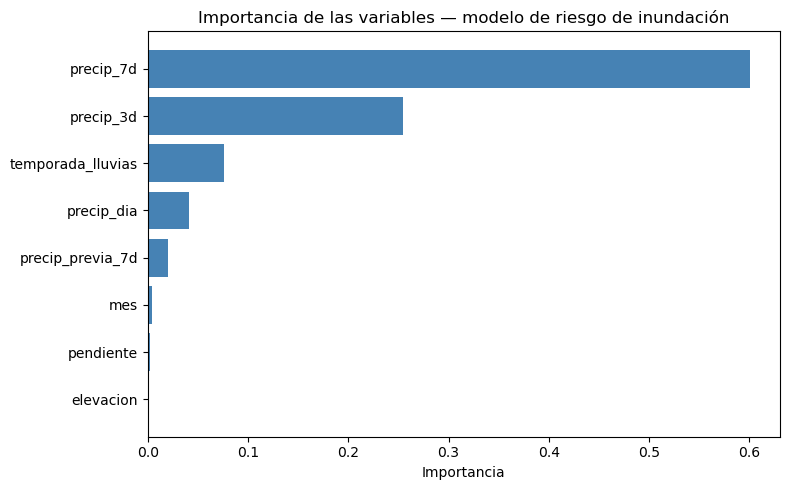

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

importancias = pd.DataFrame({
    "variable": features,
    "importancia": modelo.feature_importances_,
}).sort_values("importancia", ascending=False)

print(importancias)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancias["variable"], importancias["importancia"], color="steelblue")
ax.set_xlabel("Importancia")
ax.set_title("Importancia de las variables — modelo de riesgo de inundación")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("../data/processed/importancia_variables.png", dpi=150, bbox_inches="tight")
plt.show()

Primer enfoque del etiquetado y su descarte

El primer diseño del modelo planteó la predicción del riesgo de inundación como un problema de clasificación concurrente: para cada estación y día, determinar si las condiciones de ese mismo día constituían una situación de riesgo. La variable objetivo se definió mediante una regla de umbrales sobre la precipitación: una estación-día se etiquetaba como "riesgo" cuando la precipitación diaria superaba los 60 mm, cuando el acumulado de tres días superaba los 100 mm, o cuando se combinaba una precipitación diaria notable con un suelo previamente saturado.

El modelo XGBoost entrenado bajo este planteamiento obtuvo unas métricas aparentemente excelentes: un AUC-ROC de 1,000 y una única clasificación errónea sobre 4.703 registros del conjunto de test. Sin embargo, un análisis crítico de estos resultados reveló que no eran indicativos de un buen modelo, sino de un problema de diseño conocido como fuga de información (data leakage).

El origen del problema reside en que la variable objetivo se derivaba directamente de las mismas variables de precipitación que se proporcionaban al modelo como predictoras. Al recibir como entrada la precipitación diaria y acumulada —las mismas magnitudes con las que se había construido la etiqueta—, el modelo no estaba aprendiendo a predecir el riesgo, sino simplemente a reconstruir la regla de umbrales con la que dicha etiqueta había sido generada. El análisis de importancia de variables confirmó este diagnóstico: las variables de precipitación acumuladas concentraban más del 85 % de la importancia, mientras que las variables topográficas (elevación y pendiente) recibían una importancia prácticamente nula, al no aportar información necesaria para reproducir una fórmula que no las contenía.
Este enfoque se descartó por dos razones de fondo. En primer lugar, las métricas obtenidas carecían de validez: un rendimiento perfecto sobre un problema circular no demuestra capacidad predictiva alguna. En segundo lugar, el planteamiento no respondía al objetivo del trabajo: un sistema de alerta temprana debe anticipar una situación de riesgo, no constatar una situación ya presente a partir de datos que, en un escenario operativo real, solo estarían disponibles una vez el evento ya está ocurriendo.
La detección de esta limitación motivó un rediseño del problema hacia un enfoque de predicción anticipada, descrito en el siguiente apartado, en el que las variables predictoras corresponden a la información disponible hasta el día actual y la variable objetivo corresponde al riesgo del día siguiente. Este replanteamiento elimina la fuga de información, dota de sentido a las variables topográficas y se ajusta a la naturaleza anticipativa que debe tener un sistema de alerta temprana.

Ahora sí: el rediseño (Opción 3)
Te explico el cambio conceptual y luego vamos al código.
Antes: features del día X → predecir riesgo del día X (circular)
Ahora: features del día X → predecir riesgo del día X+1 (predicción real)
El cambio clave es que las features y la etiqueta se desfasan un día. Para cada estación:

Las features (lluvia acumulada, topografía, mes...) son las de hoy.
La etiqueta es si mañana habrá situación de riesgo.